# Flow Matching inference on Conway drums

This notebook loads the packaged `main / ratio` RingTransformer velocity model.
It uses the max-radius coordinate scale and feature statistics fitted on the
27,000 training rows. The scale-bearing feature is the standardized log of
the first eigenvalue, after the standardized log-ratios. Euler integration
takes centered Gaussian noise to a polygon. The README describes the
provenance of the packaged weights and the historical report scores.


The input is a list of 30 ascending Dirichlet eigenvalues. The output is a set of
nine-vertex polygons in the dataset's physical units. Any given Conway spectrum
has two known isospectral shapes. The two references are used only for visualization and
evaluation. The model draws every sample from the spectrum and a fresh noise realization.

Run from top to bottom for a small CPU example. Setup and the package versions
are in the archive README. The last cell optionally runs the full held-out protocol.

In [1]:
import os
from pathlib import Path
import sys

# Set JAX_PLATFORMS in the environment before opening the notebook to select another backend.
os.environ.setdefault("JAX_PLATFORMS", "cpu")
here = Path.cwd().resolve()
configured = os.environ.get("CONWAY_BUNDLE_ROOT")
if configured:
    candidates = [Path(configured).expanduser().resolve()]
else:
    candidates = [
        candidate
        for parent in (here, *here.parents)
        for candidate in (parent, parent / "results" / "conway_inference")
    ]
bundle_root = next(
    (path for path in candidates
     if (path / "inference.py").is_file() and (path / "data" / "isospectral_30k.npz").is_file()),
    None,
)
if bundle_root is None:
    raise FileNotFoundError(
        "Extract the Conway archive under the repository's results/ directory, "
        "or set CONWAY_BUNDLE_ROOT to the extracted conway_inference directory."
    )
sys.path.insert(0, str(bundle_root))

import json
import jax
import numpy as np
import matplotlib.pyplot as plt

from inference import (
    load_flow_matching, raw_test_spectra, encode_flow, sample_flow, geometry_metrics, plot_draws,
)

model, fitted, coordinate_scale, (test_features, truth_norm, twin_norm) = load_flow_matching()
print(f"Backend {jax.default_backend()} · {len(test_features):,} held-out spectra")

Backend cpu · 1,500 held-out spectra


### Turn an input spectrum into polygons

The example below takes the first four held-out rows so it can score the results against the two known twins.

For a new spectrum, use this snippet after the setup cell. Pass 30 raw, ascending eigenvalues as `new_spectrum`. A batch has shape `(n, 30)`. Plot or export the polygons directly. The test-only comparisons below require reference vertices.

```python
custom_features = encode_flow(new_spectrum, fitted)
polygons = sample_flow(model, custom_features, draws=16, steps=200) * coordinate_scale
```

In [2]:
raw = raw_test_spectra()[:4]
features = encode_flow(raw, fitted)
np.testing.assert_allclose(features, test_features[:len(raw)], rtol=1e-5, atol=1e-6)

normalized = sample_flow(model, features, seed=443, draws=4, steps=200)
samples = normalized * coordinate_scale
truth, twin = truth_norm[:len(raw)] * coordinate_scale, twin_norm[:len(raw)] * coordinate_scale
assert samples.shape == (len(raw), 4, 9, 2)
assert np.isfinite(samples).all()
print(f"Physical-coordinate array {samples.shape} · (spectra, draws, vertices, coordinates)")

Physical-coordinate array (4, 4, 9, 2) · (spectra, draws, vertices, coordinates)


### Compare the generated contours with the known twins

Pink and gray are the two known solutions. Blue is the sample. Each generated
contour is rigidly aligned with the nearer twin for display, preserving its size.

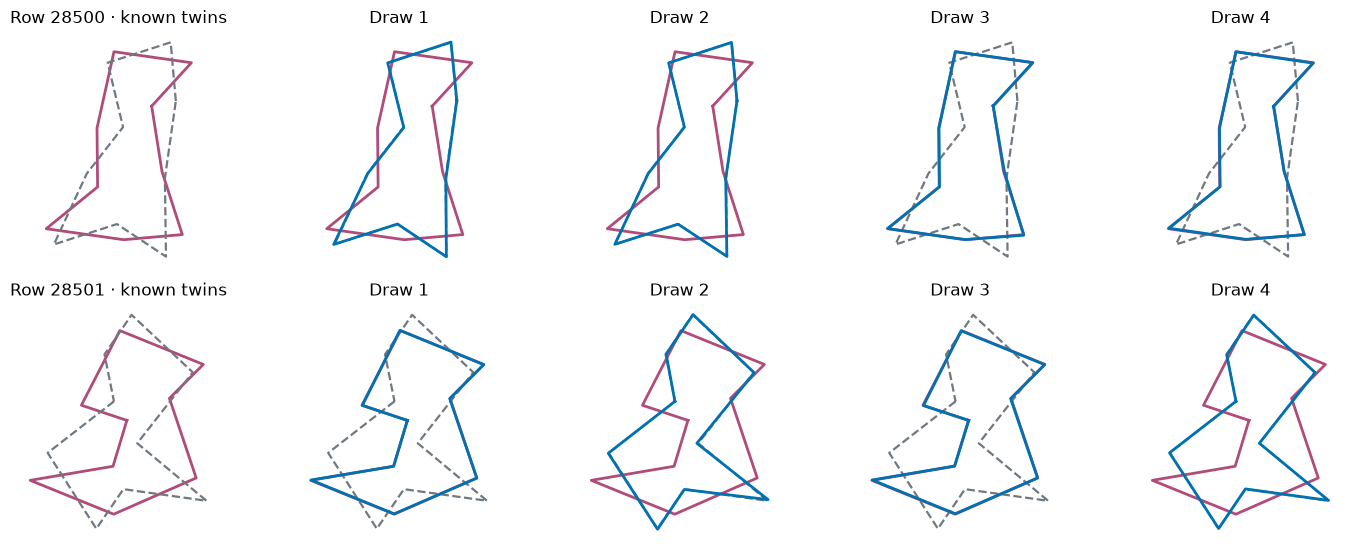

In [3]:
plot_draws(samples, truth, twin)
plt.show()

### Recompute the geometry diagnostics

The original evaluation measures vertex error after rotation, reflection, and a
cyclic or reversed vertex relabeling. A separated pair has twin distance above
0.1. A draw is sharp below one-quarter of that separation from its nearer twin
and blurry above 0.40. Both-mode coverage requires at least one sharp draw near
each twin. `pick` is measured among sharp draws. The Procrustes mean summarizes the ensemble
as a single contour. The legacy energy diagnostic uses an asymmetric distance.

On the small example, these figures describe only the displayed settings and four
inputs. The archive's shared metrics table gives the full experiment.

In [4]:
quick_metrics = geometry_metrics(normalized, truth_norm[:len(raw)], twin_norm[:len(raw)])
print(json.dumps(quick_metrics, indent=2))

{
  "draws": {
    "n_separated": 16,
    "mean_sep": 0.4075167179107666,
    "error": 0.2367616444826126,
    "error_separated": 0.2367616444826126,
    "error_set": 0.009045874699950218,
    "sharp": 1.0,
    "blurry": 0.0,
    "mean_set_over_sep": 0.032592400908470154,
    "mid_over_sep": 0.4863247275352478,
    "pick": 0.375
  },
  "mode_balance": {
    "mean_fraction_nearer_truth": 0.375,
    "std_over_drums": 0.125,
    "std_if_binomial": 0.25,
    "both_modes": 1.0
  },
  "mean_of_draws": {
    "n_separated": 4,
    "mean_sep": 0.4075166881084442,
    "error": 0.24541980028152466,
    "error_separated": 0.24541980028152466,
    "error_set": 0.16942822933197021,
    "sharp": 0.0,
    "blurry": 0.5,
    "mean_set_over_sep": 0.37357842922210693,
    "mid_over_sep": 0.12923941016197205,
    "pick": NaN
  },
  "energy_score": 0.10736680775880814,
  "mean_error_draws": 0.2367616444826126,
  "energy_score_interpretation": "Legacy asymmetric-distance diagnostic; not established as a pro

### Optional full held-out evaluation

The reference experiment draws 16 polygons per spectrum on 1,500 spectra with
Euler at 50 or 200 steps. Sampling keeps the original key allocation across
draws and spectra. `FULL_STEPS` selects the budgets to run. A full run can take
substantially longer than the example. Compare the result with the table row
for the packaged weights.

In [5]:
RUN_FULL_TEST = False
FULL_STEPS = (50, 200)
full_metrics = {}

if RUN_FULL_TEST:
    for steps in FULL_STEPS:
        draws = sample_flow(model, test_features, seed=443, draws=16, steps=steps, chunk_size=4)
        full_metrics[f"euler{steps}"] = geometry_metrics(draws, truth_norm, twin_norm)
    print(json.dumps(full_metrics, indent=2))
else:
    print("Set RUN_FULL_TEST = True to sample all 1,500 held-out spectra at the selected budgets.")

Set RUN_FULL_TEST = True to sample all 1,500 held-out spectra at the selected budgets.
